# Experiment 8 — Classification Models (Titanic Dataset)

**Covers:** Logistic Regression, KNN, Gaussian Naïve Bayes, accuracy, precision, recall, F1, AUC, odds ratios, confusion matrices, classification reports, ROC curves, KNN hyperparameter analysis and CSV results.

**Dataset:** **Titanic** – `train.csv` from the Kaggle Titanic competition ([kaggle.com/c/titanic](https://www.kaggle.com/competitions/titanic/data)), 891 passengers, columns `PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked`.

**Data file:** keep `train.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\train.csv")`).

**Remember:** Split → Three models → fit/predict/probability → Metrics → ROC → Odds → K values → Compare.

Target: `Survived` (0 = died, 1 = survived). `Sex` is encoded as 0/1 so it can be used as a feature.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("train.csv")

## 1. Prepare data

In [2]:
cols = ["Sex", "Age", "Fare", "Pclass", "SibSp", "Parch"]
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
data = df[cols + ["Survived"]].dropna()

X = data[cols]
y = data["Survived"]

print("Class mapping: 0 = Died, 1 = Survived")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Died, 1 = Survived
Survived
0    424
1    290
Name: count, dtype: int64
Train: 571 Test: 143


## 2. Models (same loop for all three)


 Logistic
              precision    recall  f1-score   support

           0       0.83      0.82      0.83        85
           1       0.75      0.76      0.75        58

    accuracy                           0.80       143
   macro avg       0.79      0.79      0.79       143
weighted avg       0.80      0.80      0.80       143



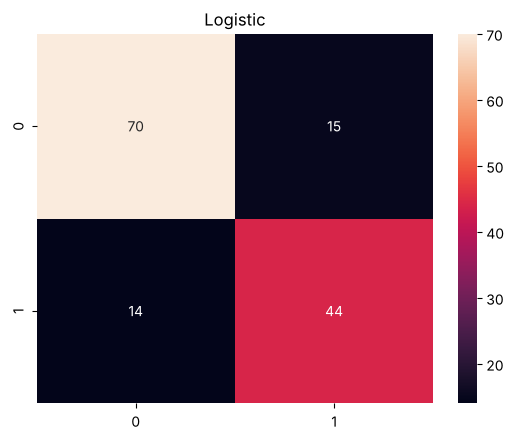


 KNN
              precision    recall  f1-score   support

           0       0.79      0.81      0.80        85
           1       0.71      0.69      0.70        58

    accuracy                           0.76       143
   macro avg       0.75      0.75      0.75       143
weighted avg       0.76      0.76      0.76       143



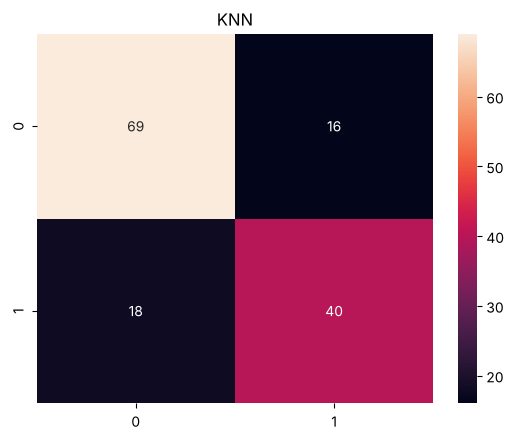


 Naive Bayes
              precision    recall  f1-score   support

           0       0.82      0.79      0.80        85
           1       0.70      0.74      0.72        58

    accuracy                           0.77       143
   macro avg       0.76      0.76      0.76       143
weighted avg       0.77      0.77      0.77       143



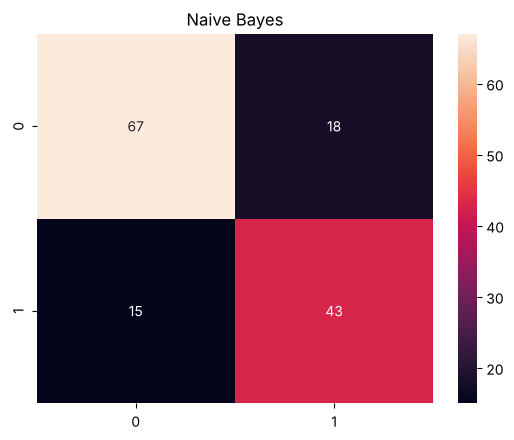

In [3]:
models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB())
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

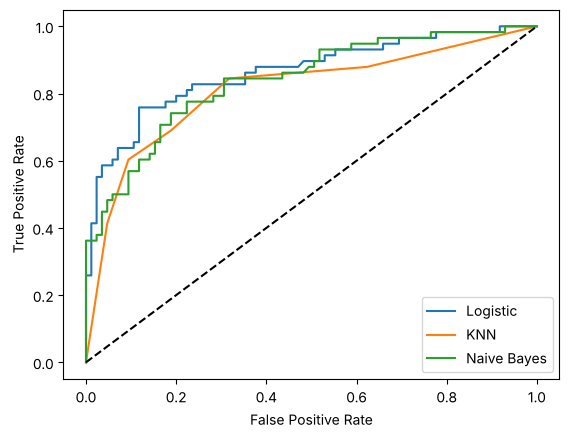

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Logistic regression coefficients and odds ratio

In [5]:
coef = models["Logistic"].named_steps["logisticregression"].coef_[0]
odds = pd.DataFrame({
    "Coefficient": coef,
    "Odds Ratio": np.exp(coef)
}, index=cols)
print(odds)

        Coefficient  Odds Ratio
Sex        1.218097    3.380748
Age       -0.640967    0.526783
Fare       0.066805    1.069087
Pclass    -1.041187    0.353035
SibSp     -0.323030    0.723952
Parch     -0.013232    0.986856


## 5. Effect of K (5-fold CV)

    K  Accuracy        F1       AUC
0   1  0.784592  0.737761  0.779108
1   3  0.810862  0.760614  0.845075
2   5  0.817879  0.767902  0.858552
3   7  0.800336  0.741767  0.862791
4   9  0.802014  0.748616  0.859669
5  11  0.803768  0.751073  0.857330
6  15  0.809001  0.759778  0.862820
Best K: 15


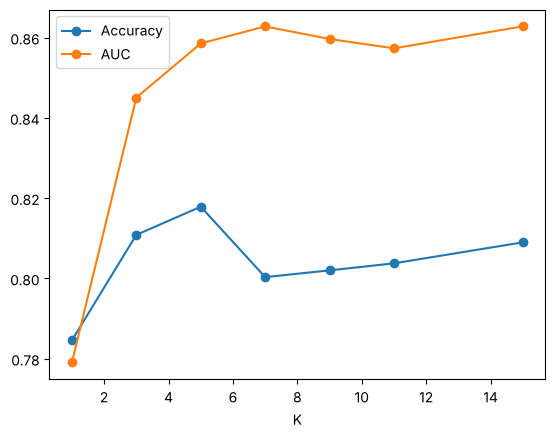

In [6]:
rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([k, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

knn = pd.DataFrame(rows, columns=["K", "Accuracy", "F1", "AUC"])
print(knn)
print("Best K:", knn.loc[knn["AUC"].idxmax(), "K"])

knn.plot(x="K", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 6. Comparison and save

             Accuracy  Precision    Recall        F1       AUC
Model                                                         
Logistic     0.797203   0.745763  0.758621  0.752137  0.863793
KNN          0.762238   0.714286  0.689655  0.701754  0.811258
Naive Bayes  0.769231   0.704918  0.741379  0.722689  0.839858


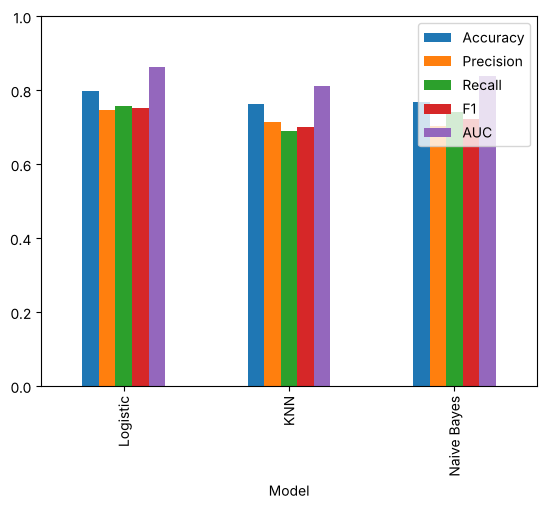

Saved classification.csv, logistic_coefficients.csv, knn_results.csv


In [7]:
result = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("classification.csv")
odds.to_csv("logistic_coefficients.csv")
knn.to_csv("knn_results.csv", index=False)
print("Saved classification.csv, logistic_coefficients.csv, knn_results.csv")

## Result / Conclusion
- 714 passengers with known age (571 train / 143 test); target `Survived`.
- **Logistic Regression is best:** accuracy 0.797, F1 0.752, AUC 0.864. Naive Bayes: 0.769 (AUC 0.840); KNN (K = 5): 0.762 (AUC 0.811).
- Odds ratios: being female multiplies the odds of survival by 3.4; each higher class number (lower class) multiplies them by 0.35; older age lowers them (0.53 per SD).
- K tuning: CV AUC rises from 0.78 (K = 1) to about 0.86 for K ≥ 7; best K = 15.